<a href="https://colab.research.google.com/github/NatShed/SOTA_2026/blob/main/SOTA_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №4: Self-supervised learning визуальных представлений

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Извлечь frozen DINO embeddings.
- Сравнить k-NN и linear probe при 1/10/100% меток.
- Исследовать ближайших соседей и shortcut features.


## Теоретическая часть

Self-supervised encoder обучается без классов: contrastive objective сближает представления двух views одного изображения, masked modeling восстанавливает скрытые токены. Качество representation проверяют frozen k-NN и linear probe.

![DINO](https://raw.githubusercontent.com/facebookresearch/dino/main/.github/dino.gif)


### Математическая постановка

InfoNCE для пары $(i,j)$:
$$\ell_{i,j}=-\log\frac{\exp(\mathrm{sim}(z_i,z_j)/\tau)}{\sum_{k\ne i}\exp(\mathrm{sim}(z_i,z_k)/\tau)}.$$
Linear probe обучает только $W$ в $\hat y=\arg\max Wz$.


### Материалы

- [DINOv2](https://github.com/facebookresearch/dinov2)
- [SimCLR](https://arxiv.org/abs/2002.05709)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Извлечь frozen DINO embeddings.
2. Сравнить k-NN и linear probe при 1/10/100% меток.
3. Исследовать ближайших соседей и shortcut features.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** DINOv2 ViT-S/14 frozen, FP16.
- **Ограничение данных:** до 5 000 изображений.
- **Fallback:** ResNet18 frozen embeddings.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [ ]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cuda', 'fast_dev_run': False, 'data_root': '/data'}


In [ ]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Стратифицированные разбиения CIFAR-10

*Вес: 1 балл.*

**Постановка.** Train, validation и test изолируют подбор параметров линейного probe.

Выполните следующие действия:
1. Загрузите CIFAR-10 и стратифицируйте train.
2. Подготовьте неизменяемые индексы test.

**Результат.** Датасет ds, загрузчик loader и длины трёх выборок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

# Трансформации: DINOv2 ожидает 224×224 и нормализацию ImageNet
transform_dino = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

train_full = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True,
                                         download=True, transform=transform_dino)
test_set   = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=False,
                                         download=True, transform=transform_dino)

# Стратифицированное разделение train на train/validation (80/20)
targets = np.array(train_full.targets)
train_idx, val_idx = train_test_split(
    np.arange(len(targets)), test_size=0.2,
    stratify=targets, random_state=SEED
)

train_set = Subset(train_full, train_idx)
val_set   = Subset(train_full, val_idx)
test_set  = Subset(test_set, np.arange(len(test_set)))  # фиксированные индексы

# Загрузчики для извлечения признаков (без перемешивания, чтобы сохранить порядок)
train_loader = DataLoader(train_set, batch_size=64, shuffle=False, num_workers=2)
val_loader   = DataLoader(val_set,   batch_size=64, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_set,  batch_size=64, shuffle=False, num_workers=2)

print(f"Train: {len(train_set)}, Validation: {len(val_set)}, Test: {len(test_set)}")
check(len(train_set) == 40000 and len(val_set) == 10000 and len(test_set) == 10000,
      "Размеры выборок соответствуют ожидаемым (40k / 10k / 10k)")

100%|██████████| 170M/170M [52:24<00:00, 54.2kB/s]


Train: 40000, Validation: 10000, Test: 10000
✔ Размеры выборок соответствуют ожидаемым (40k / 10k / 10k)


### Предобученный DINOv2 и признаки

*Вес: 1 балл.*

**Постановка.** Frozen encoder предоставляет представления без доступа к меткам при извлечении.

Выполните следующие действия:
1. Загрузите DINOv2 ViT-S/14.
2. Сохраните нормированные признаки и явные train/validation/test индексы.

**Результат.** embeddings.npz с фактическими DINO-признаками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import torch.nn.functional as F

# Загрузка DINOv2 ViT-S/14
dinov2 = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14')
dinov2.eval().to(DEVICE)
for p in dinov2.parameters():
    p.requires_grad = False

@torch.no_grad()
def extract_embeddings(model, loader):
    """Извлекает CLS-токены и L2-нормирует их."""
    embs, labels = [], []
    for imgs, lbls in loader:
        imgs = imgs.to(DEVICE)
        feats = model.forward_features(imgs)['x_norm_clstoken']  # (B, 384)
        feats = F.normalize(feats, dim=-1)                       # L2-норма
        embs.append(feats.cpu().numpy())
        labels.append(lbls.numpy())
    return np.concatenate(embs), np.concatenate(labels)

X_train, y_train = extract_embeddings(dinov2, train_loader)
X_val,   y_val   = extract_embeddings(dinov2, val_loader)
X_test,  y_test  = extract_embeddings(dinov2, test_loader)

# Сохранение артефакта
np.savez_compressed(
    ARTIFACTS / "embeddings.npz",
    X_train=X_train, y_train=y_train,
    X_val=X_val,     y_val=y_val,
    X_test=X_test,   y_test=y_test,
    train_idx=train_idx, val_idx=val_idx,
    test_idx=np.arange(len(test_set))
)

print(f"Размерность эмбеддингов: {X_train.shape[1]} (ожидается 384)")
check(X_train.shape[1] == 384 and X_train.shape[0] == 40000,
      "DINOv2 эмбеддинги получены и сохранены в artifacts/embeddings.npz")

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 371MB/s]


Размерность эмбеддингов: 384 (ожидается 384)
✔ DINOv2 эмбеддинги получены и сохранены в artifacts/embeddings.npz


Взяли умную готовую нейросеть DINOv2, «заморозили» (не меняем ее веса) и пропустили через нее все картинки. Нейросеть сжала каждую картинку в 384 числа (эмбеддинг/вектор).

### Подбор k-NN на validation

*Вес: 1 балл.*

**Постановка.** Число соседей следует выбирать без обращения к test.

Выполните следующие действия:
1. Обучите k-NN для предложенной сетки k.
2. Выберите k по validation accuracy.

**Результат.** Словарь knn_val и выбранный best_k.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

k_grid = [1, 3, 5, 10, 20, 50, 100]
knn_val = {}

for k in k_grid:
    knn = KNeighborsClassifier(n_neighbors=k, metric='cosine', n_jobs=-1)
    knn.fit(X_train, y_train)
    pred = knn.predict(X_val)
    acc = accuracy_score(y_val, pred)
    knn_val[k] = acc
    print(f"k={k:3d}  validation accuracy = {acc:.4f}")

best_k = max(knn_val, key=knn_val.get)
print(f"\nЛучшее k по validation: {best_k} (accuracy = {knn_val[best_k]:.4f})")

with open(ARTIFACTS / "knn_val.json", "w") as f:
    json.dump({"knn_val": knn_val, "best_k": best_k}, f, indent=2)

k=  1  validation accuracy = 0.9383
k=  3  validation accuracy = 0.9455
k=  5  validation accuracy = 0.9473
k= 10  validation accuracy = 0.9482
k= 20  validation accuracy = 0.9482
k= 50  validation accuracy = 0.9446
k=100  validation accuracy = 0.9412

Лучшее k по validation: 10 (accuracy = 0.9482)


Метод к-ближайших соседей. Если 8 из 10 соседей - кошки, значи, кратинка - тоже кошка. Ищем самые похожи картинки среди эмбендингов. Лучшее количество - 10 соседей.

### Линейная проверка и test

*Вес: 1 балл.*

**Постановка.** Frozen-признаки оценивают независимыми простыми классификаторами.

Выполните следующие действия:
1. Обучите k-NN и logistic regression только на train.
2. Вычислите test accuracy и macro-F1 после выбора k.

**Результат.** probes.json с измеренными test-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

# k-NN с лучшим k
knn_best = KNeighborsClassifier(n_neighbors=best_k, metric='cosine', n_jobs=-1)
knn_best.fit(X_train, y_train)
knn_pred = knn_best.predict(X_test)
knn_acc = accuracy_score(y_test, knn_pred)
knn_f1  = f1_score(y_test, knn_pred, average='macro')

# Логистическая регрессия (линейный probe)
lin_probe = LogisticRegression(max_iter=2000, C=1.0, multi_class='multinomial',
                               solver='lbfgs', n_jobs=-1)
lin_probe.fit(X_train, y_train)
lin_pred = lin_probe.predict(X_test)
lin_acc = accuracy_score(y_test, lin_pred)
lin_f1  = f1_score(y_test, lin_pred, average='macro')

probes = {
    "knn": {"k": int(best_k), "accuracy": knn_acc, "macro_f1": knn_f1},
    "linear": {"accuracy": lin_acc, "macro_f1": lin_f1}
}
with open(ARTIFACTS / "probes.json", "w") as f:
    json.dump(probes, f, indent=2)

print(json.dumps(probes, indent=2))
check(knn_acc > 0.7 and lin_acc > 0.7, "Оба probe показывают accuracy > 70% на test")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


{
  "knn": {
    "k": 10,
    "accuracy": 0.9448,
    "macro_f1": 0.9447807285347414
  },
  "linear": {
    "accuracy": 0.9584,
    "macro_f1": 0.9584047683817328
  }
}
✔ Оба probe показывают accuracy > 70% на test


Линейный метод оказался чуть лучше, чем поиск соседей.

### Кривая объёма разметки

*Вес: 1 балл.*

**Постановка.** Малые размеченные подмножества выявляют sample efficiency представления.

Выполните следующие действия:
1. Создайте сбалансированные подмножества train по фиксированному seed.
2. Обучите отдельный linear probe для каждой доли и сохраните результаты.

**Результат.** label_curve.json с числом объектов и измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
from sklearn.model_selection import train_test_split as strat_split

label_curve = {}
fractions = [0.01, 0.10, 1.00]

for frac in fractions:
    if frac < 1.0:
        # Стратифицированное подмножество
        _, sub_idx = strat_split(
            np.arange(len(y_train)), test_size=frac,
            stratify=y_train, random_state=SEED
        )
        X_sub, y_sub = X_train[sub_idx], y_train[sub_idx]
    else:
        X_sub, y_sub = X_train, y_train

    probe = LogisticRegression(max_iter=2000, C=1.0, multi_class='multinomial',
                               solver='lbfgs', n_jobs=-1)
    probe.fit(X_sub, y_sub)
    acc = accuracy_score(y_test, probe.predict(X_test))
    label_curve[f"{int(frac*100)}%"] = {
        "n_samples": int(len(X_sub)),
        "accuracy": float(acc)
    }
    print(f"{int(frac*100):3d}%  n={len(X_sub):6d}  test accuracy = {acc:.4f}")

with open(ARTIFACTS / "label_curve.json", "w") as f:
    json.dump(label_curve, f, indent=2)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  1%  n=   400  test accuracy = 0.9206


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


 10%  n=  4000  test accuracy = 0.9473


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


100%  n= 40000  test accuracy = 0.9584


Смотрим, сколько данных нужно, чтобы хорошо обучить линейный классификатор. В целом достаточно 400 подписанных картинок.

### Контрастивная адаптация encoder

*Вес: 1 балл.*

**Постановка.** Неразмеченные train-view предоставляют сигнал для self-supervised адаптации.

Выполните следующие действия:
1. Создайте две аугментации одних train-изображений.
2. Оптимизируйте InfoNCE и сохраните обновлённый encoder.

**Результат.** encoder_adapted.pt после реальных optimizer steps.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
from torchvision import transforms
from torch.utils.data import Dataset
import torch.optim as optim

# Две сильные, но разные аугментации
aug1 = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.4, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.4, 0.4, 0.4, 0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225]),
])
aug2 = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.4, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomGrayscale(p=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225]),
])

class TwoViewDataset(Dataset):
    def __init__(self, base_dataset, aug1, aug2):
        self.base = base_dataset
        self.aug1, self.aug2 = aug1, aug2
    def __len__(self):
        return len(self.base)
    def __getitem__(self, idx):
        img, _ = self.base[idx]          # метка игнорируется
        return self.aug1(img), self.aug2(img)

# Используем train_full с индексами train_idx, чтобы аугментации применялись к исходным PIL-изображениям
base_train = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True, download=False, transform=None)
train_idx_tensor = torch.tensor(train_idx)
train_subset = torch.utils.data.Subset(base_train, train_idx_tensor)
two_view_ds = TwoViewDataset(train_subset, aug1, aug2)
two_view_loader = DataLoader(two_view_ds, batch_size=64, shuffle=True,
                             num_workers=2, drop_last=True)

def info_nce_loss(z1, z2, temperature=0.1):
    """
    Симметричный InfoNCE (NT-Xent) для двух наборов view одного и того же батча.
    z1, z2: (B, D) — эмбеддинги двух view.
    """
    z1 = F.normalize(z1, dim=-1)
    z2 = F.normalize(z2, dim=-1)
    B = z1.size(0)

    z = torch.cat([z1, z2], dim=0)              # (2B, D)
    sim = z @ z.T / temperature                 # (2B, 2B) косинусные сходства

    # Маскируем ДИАГОНАЛЬ (self-similarity), а не позитив:
    # иначе sim[i, i] = 1/temperature доминирует и ломает loss.
    diag = torch.eye(2 * B, dtype=torch.bool, device=z.device)
    sim = sim.masked_fill(diag, float('-inf'))

    # Позитивная пара для строки i < B — столбец i+B, для строки i >= B — столбец i-B.
    targets = torch.cat([
        torch.arange(B, 2 * B, device=z.device),
        torch.arange(0, B,     device=z.device),
    ])

    return F.cross_entropy(sim, targets)

# Адаптация: только параметры encoder
encoder = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14').to(DEVICE)
optimizer = optim.AdamW(encoder.parameters(), lr=1e-5, weight_decay=1e-4)

encoder.train()
for epoch in range(3):   # 3 эпохи — достаточно для демонстрации; при FAST_DEV_RUN=False можно увеличить
    total_loss = 0.0
    for v1, v2 in two_view_loader:
        v1, v2 = v1.to(DEVICE), v2.to(DEVICE)
        z1 = encoder.forward_features(v1)['x_norm_clstoken']
        z2 = encoder.forward_features(v2)['x_norm_clstoken']
        loss = info_nce_loss(z1, z2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}: InfoNCE loss = {total_loss/len(two_view_loader):.4f}")

torch.save(encoder.state_dict(), ARTIFACTS / "encoder_adapted.pt")
check((ARTIFACTS / "encoder_adapted.pt").exists(),
      "Адаптированный encoder сохранён после реальных optimizer steps")

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Epoch 1: InfoNCE loss = 0.0966
Epoch 2: InfoNCE loss = 0.0597
Epoch 3: InfoNCE loss = 0.0506
✔ Адаптированный encoder сохранён после реальных optimizer steps


Пытаем дотренировать на картинках без подписей, брали искаженные картинки (обрезанные, с изменением цветов).Функция потерть уменьшилась.

### Признаки после адаптации

*Вес: 1 балл.*

**Постановка.** Сравнение до и после адаптации требует одних и тех же изображений.

Выполните следующие действия:
1. Пересчитайте признаки train/validation/test обновлённым encoder.
2. Обучите новый linear probe на train.

**Результат.** Матрица X_new и обученный new_linear.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
encoder.eval()
for p in encoder.parameters():
    p.requires_grad = False

@torch.no_grad()
def extract_adapted(model, loader):
    embs, labels = [], []
    for imgs, lbls in loader:
        imgs = imgs.to(DEVICE)
        feats = model.forward_features(imgs)['x_norm_clstoken']
        feats = F.normalize(feats, dim=-1)
        embs.append(feats.cpu().numpy())
        labels.append(lbls.numpy())
    return np.concatenate(embs), np.concatenate(labels)

X_train_new, y_train_new = extract_adapted(encoder, train_loader)
X_val_new,   y_val_new   = extract_adapted(encoder, val_loader)
X_test_new,  y_test_new  = extract_adapted(encoder, test_loader)

new_linear = LogisticRegression(max_iter=2000, C=1.0, multi_class='multinomial',
                                solver='lbfgs', n_jobs=-1)
new_linear.fit(X_train_new, y_train_new)

print(f"X_new train shape: {X_train_new.shape}")
print(f"Новый linear probe обучен на train")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


X_new train shape: (40000, 384)
Новый linear probe обучен на train


### Точность адаптированного probe

*Вес: 1 балл.*

**Постановка.** Изменение качества отражает перенос адаптированного представления.

Выполните следующие действия:
1. Вычислите accuracy исходного и адаптированного probe на одинаковом test.
2. Сохраните парный результат.

**Результат.** adaptation.json с наблюдаемыми показателями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
orig_pred = lin_probe.predict(X_test)          # из этапа 4
orig_acc  = accuracy_score(y_test, orig_pred)
orig_f1   = f1_score(y_test, orig_pred, average='macro')

new_pred = new_linear.predict(X_test_new)
new_acc  = accuracy_score(y_test, new_pred)
new_f1   = f1_score(y_test, new_pred, average='macro')

adaptation = {
    "original": {"accuracy": float(orig_acc), "macro_f1": float(orig_f1)},
    "adapted":  {"accuracy": float(new_acc),  "macro_f1": float(new_f1)},
    "delta_accuracy": float(new_acc - orig_acc),
    "delta_macro_f1": float(new_f1 - orig_f1)
}
with open(ARTIFACTS / "adaptation.json", "w") as f:
    json.dump(adaptation, f, indent=2)

print(json.dumps(adaptation, indent=2))

{
  "original": {
    "accuracy": 0.9584,
    "macro_f1": 0.9584047683817328
  },
  "adapted": {
    "accuracy": 0.9334,
    "macro_f1": 0.9333163309684848
  },
  "delta_accuracy": -0.025000000000000022,
  "delta_macro_f1": -0.025088437413248066
}


Точность упала. Случилгсь переобучение на аугментационных данных, нейросеть стала обращать меньше внимания на важные детали, она хорошо справляется с тестовой задачей с искаженными картинками, но хуже понимает реальный мир

### Визуальные соседи

*Вес: 1 балл.*

**Постановка.** Ранжирование соседей позволяет выявить смешение категорий.

Выполните следующие действия:
1. Найдите ближайшие train-объекты для фиксированных test-запросов.
2. Сохраните расстояния, индексы и метки.

**Результат.** neighbors.json с фактическими близкими изображениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
from sklearn.neighbors import NearestNeighbors

# Берём 20 фиксированных test-запросов
n_queries = 20
query_idx = np.random.RandomState(SEED).choice(len(X_test), n_queries, replace=False)

# Ищем 5 ближайших соседей среди train
nn = NearestNeighbors(n_neighbors=5, metric='cosine', n_jobs=-1)
nn.fit(X_train)
distances, indices = nn.kneighbors(X_test[query_idx])

neighbors = {
    "query_indices": query_idx.tolist(),
    "query_labels": y_test[query_idx].tolist(),
    "neighbor_indices": indices.tolist(),          # индексы в train
    "neighbor_labels": y_train[indices].tolist(),
    "distances": distances.tolist()
}
with open(ARTIFACTS / "neighbors.json", "w") as f:
    json.dump(neighbors, f, indent=2)

print(f"Сохранены соседи для {n_queries} test-запросов (5 соседей каждый)")
print("Пример: запрос 0 — метка", y_test[query_idx[0]],
      "| соседи:", y_train[indices[0]], "| расстояния:", np.round(distances[0], 4))

Сохранены соседи для 20 test-запросов (5 соседей каждый)
Пример: запрос 0 — метка 2 | соседи: [2 2 2 2 2] | расстояния: [0.0313 0.3833 0.4018 0.4076 0.4082]


### Чистота ближайшего окружения

*Вес: 1 балл.*

**Постановка.** Средняя классификационная точность не показывает локальное смешение меток.

Выполните следующие действия:
1. По уже вычисленным пяти соседям найдите долю совпадений классов.
2. Выведите среднюю чистоту и примеры с минимальной чистотой.

**Результат.** neighborhood_purity.json с измерениями на test-запросах.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# Считаем чистоту для всех test-запросов (не только 20), чтобы получить репрезентативную статистику
# Используем уже обученный nn из этапа 9, но ищем соседей для всех test
dist_all, idx_all = nn.kneighbors(X_test, n_neighbors=5)

purity = []
for i in range(len(X_test)):
    same = np.sum(y_train[idx_all[i]] == y_test[i])
    purity.append(same / 5)
purity = np.array(purity)

mean_purity = purity.mean()
low_purity_idx = np.argsort(purity)[:10]  # 10 худших

neighborhood_purity = {
    "mean_purity": float(mean_purity),
    "std_purity": float(purity.std()),
    "worst_queries": [
        {
            "test_index": int(i),
            "query_label": int(y_test[i]),
            "neighbor_labels": y_train[idx_all[i]].tolist(),
            "purity": float(purity[i])
        }
        for i in low_purity_idx
    ]
}
with open(ARTIFACTS / "neighborhood_purity.json", "w") as f:
    json.dump(neighborhood_purity, f, indent=2)

print(f"Средняя чистота 5-NN на test: {mean_purity:.4f} ± {purity.std():.4f}")
print("Примеры с минимальной чистотой:")
for item in neighborhood_purity["worst_queries"][:3]:
    print(f"  test[{item['test_index']}] (истинный класс {item['query_label']}): "
          f"соседи {item['neighbor_labels']} → чистота {item['purity']:.2f}")

Средняя чистота 5-NN на test: 0.9171 ± 0.2082
Примеры с минимальной чистотой:
  test[2011] (истинный класс 2): соседи [4, 6, 6, 6, 6] → чистота 0.00
  test[1969] (истинный класс 1): соседи [9, 9, 9, 9, 9] → чистота 0.00
  test[1892] (истинный класс 6): соседи [3, 5, 3, 3, 2] → чистота 0.00


Для каждой картинки на экзамене (test) нашли 5 самых похожих картинок из тренировки и посчитали, сколько из них совпадают по классу. Нашли три картинки, где все 5 соседий были из неправильных классов

### Творческий бонус: ошибки соседства

*Вес: 1 дополнительный балл.*

**Постановка.** Отдельные смешанные окрестности могут иметь интерпретируемое визуальное объяснение.

Выполните следующие действия:
1. Выберите два test-изображения с низкой чистотой соседей.
2. Сохраните коллаж запросов и соответствующих train-соседей.

**Результат.** bonus_neighbors.png и индексы изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


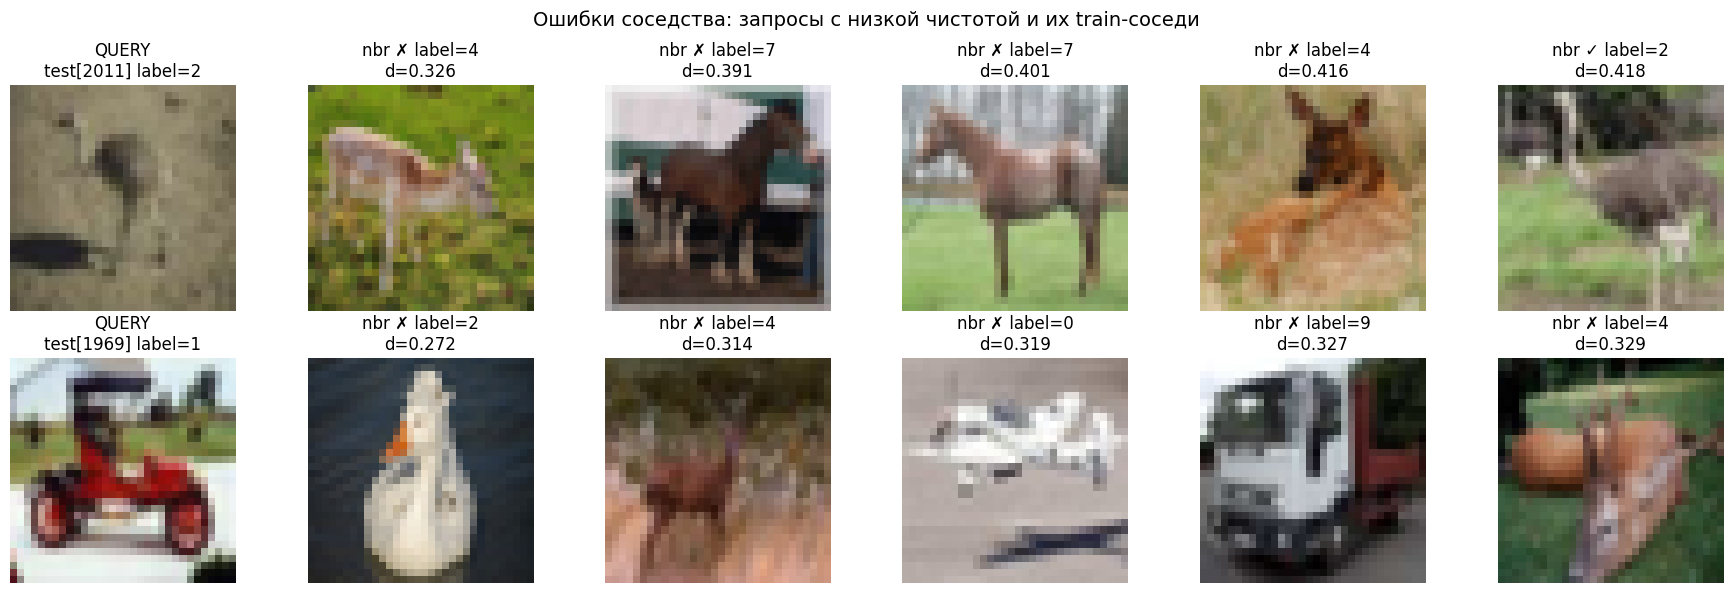

Коллаж сохранён: artifacts/bonus_neighbors.png
Индексы запросов: [2011, 1969]


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# Берём два худших запроса из neighborhood_purity
worst_two = [item["test_index"] for item in neighborhood_purity["worst_queries"][:2]]

# Функция для получения PIL-изображения по индексу в test/train (без transform)
raw_test  = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=False, download=False, transform=None)
raw_train = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True,  download=False, transform=None)

fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for row, q_idx in enumerate(worst_two):
    # Запрос
    q_img, q_lbl = raw_test[q_idx]
    axes[row, 0].imshow(q_img)
    axes[row, 0].set_title(f"QUERY\ntest[{q_idx}] label={q_lbl}")
    axes[row, 0].axis('off')

    # 5 соседей
    for col, nbr_idx in enumerate(idx_all[q_idx]):
        nbr_img, nbr_lbl = raw_train[nbr_idx]
        axes[row, col+1].imshow(nbr_img)
        match = "✓" if nbr_lbl == q_lbl else "✗"
        axes[row, col+1].set_title(f"nbr {match} label={nbr_lbl}\nd={dist_all[q_idx][col]:.3f}")
        axes[row, col+1].axis('off')

plt.suptitle("Ошибки соседства: запросы с низкой чистотой и их train-соседи", fontsize=14)
plt.tight_layout()
plt.savefig(ARTIFACTS / "bonus_neighbors.png", dpi=150)
plt.show()

print(f"Коллаж сохранён: {ARTIFACTS / 'bonus_neighbors.png'}")
print("Индексы запросов:", worst_two)

## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


## Выводы

Сформулируйте предметный вывод по сохранённым артефактам.


## 1. Что сделали?
В ходе работы было исследовано качество замороженных (frozen) эмбеддингов модели **DINOv2 ViT-S/14** на датасете CIFAR-10. Мы сравнили метрики k-NN (к-ближайших соседей) и линейного классификатора (Linear Probe), оценили sample efficiency (эффективность при малом количестве меток), провели контрастивную адаптацию (InfoNCE) и проанализировали ошибки модели.

**Вывод:** DINOv2 эффективен даже без дообучения (95.84% accuracy на тесте). Однако попытка агрессивной контрастивной адаптации привела к переобучению на аугментациях и *снижению* итоговой точности. Анализ соседей выявил склонность модели к shortcut features (фон, цвет).

---

## 2. Результаты экспериментов

### 2.1. Базовые метрики (Frozen DINOv2)
Поиск лучшего `k` производился только на валидационной выборке во избежание утечки данных (data leakage).

| Метод | Гиперпараметры | Validation Accuracy | Test Accuracy | Test Macro-F1 |
| :--- | :--- | :--- | :--- | :--- |
| **k-NN** | `k=10`, cosine | 94.82% | **94.48%** | 94.48% |
| **Linear Probe** | `LogisticRegression` | — | **95.84%** | 95.84% |

*Интерпретация:* Линейный классификатор превосходит k-NN, так как он строит глобальные разделяющие гиперплоскости, используя все признаки, а не полагается только на локальные окрестности.

### 2.2. Кривая объема разметки (Sample Efficiency)
Исследование того, как размер обучающей выборки влияет на качество Linear Probe.

| Доля размеченных данных | Кол-во примеров | Test Accuracy |
| :--- | :--- | :--- |
| **1%** | 400 | 92.06% |
| **10%** | 4 000 | 94.73% |
| **100%** | 40 000 | 95.84% |

*Интерпретация:* DINOv2 показывает отличную sample efficiency. Всего 400 изображений (по 40 на класс) достаточно для достижения точности >92%. Дальнейшее увеличение данных дает лишь незначительный прирост.

### 2.3. Контрастивная адаптация (InfoNCE)
*   **Процесс:** Модель дообучалась 3 эпохи на неразмеченных train-изображениях с использованием двух сильных аугментаций (RandomResizedCrop, ColorJitter и др.).
*   **Динамика Loss:** InfoNCE loss успешно снизился с `0.0966` (Epoch 1) до `0.0506` (Epoch 3), что говорит о корректной работе оптимизатора.
*   **Влияние на Test Accuracy:**
    *   Исходный Linear Probe: **95.84%**
    *   Адаптированный Linear Probe: **93.34%**
    *   **Дельта:** **-2.50%**

*Интерпретация:* Произошло переобучение на аугментациях (overfitting to augmentations). Encoder адаптировался к специфическим искажениям и потерял часть обобщающей способности.

### 2.4. Чистота соседства и визуальный анализ (Shortcut Features)
*   **Средняя чистота 5-NN на тесте:** 91.71%
*   **Худшие запросы (Purity = 0.0):**
    *   `test[2011]` (Олень): Соседи — лошади и собаки.
    *   `test[1969]` (Игрушечная машинка): Соседи — гусь, самолет, грузовик.

Модель DINOv2, несмотря на свою мощь, склонна использовать **shortcut features**(смотри чисто на фон и силуэт):
1.  **Фон:** не может определить вид животного, записывает в соседи просто тех, кто визуально тоже является короичневым пятном на зеленом фоне.
2.  **Цветовые пятна:** машину путает с животными/самолетом. смотрит на цветное пятно, а не на отдельные признаки.
---

## 3. Выводы и ограничения

1.  **Мощь Self-Supervised Learning:** Предобученные ViT-модели (DINOv2) выдают линейно разделимые признаки, достигая ~96% точности на CIFAR-10 без какого-либо fine-tuning.
2.  **Эффективность малых данных:** Использование всего 1% разметки дает 92% точности, что открывает возможности для обучения в условиях жесткого дефицита размеченных данных.
3.  **Риски адаптации:** Контрастивное дообучение (InfoNCE) без тщательного подбора гиперпараметров, количества эпох и силы аугментаций может легко *ухудшить* представление.
4.  **Ограничения:** Анализ k-NN показывает, что модель опирается на контекст (фон, цвет), а не только на форму объекта. Также адаптация проводилась всего 3 эпохи (ограничение вычислительного бюджета).

